# 41 · 분산·공분산으로 표현 제약하기

📎 **이번 질문** · 두 촬영의 특징은 맞추면서 서로 다른 과일과 특징 차원은 구분하려면 무엇을 더해야 할까요?

준비물: 11 선형대수의 중심화, 12 분산·공분산, [40 교사·학생](40_teacher_student.ipynb), 03·04의 미분·Adam. NumPy·CPU float64만 사용하며 다른 노트북 실행 상태나 다운로드에 의존하지 않습니다. 과일의 상태와 촬영 조건을 단순화한 합성 자료로 수식부터 실제 학습까지 연결합니다.

| 표시 | 뜻 | 읽는 법 |
|---|---|---|
| 🔑 | 핵심 | 축과 기울기 경로를 씁니다 |
| 🔍 | 확인 | 그림·손계산·독립 평가를 대조합니다 |
| 📎 | 참고 | 처음 나온 용어·관용구를 풀이합니다 |
| ✏️ | 연습 | 한두 줄을 채우고 검사합니다 |

**이 노트북에서 반드시 가져갈 세 가지**

1. 정렬은 두 뷰를 가깝게 하고, 분산 하한은 상수 해에 비용을 부여합니다.
2. 공분산 벌점은 복제 특징을 드러내지만 통계적 독립성까지 보장하지 않습니다.
3. 각 항의 분모와 전체 미분을 검산한 뒤 목적항 제거 실험을 독립 평가합니다.

[학습 경로](../../docs/CURRICULUM.md) · [그림 보조 코드](../../src/utils/variance_covariance_plots.py)

In [1]:
# 준비 셀: 그림과 독립 미분 검산 도구입니다.
import sys
from pathlib import Path
import numpy as np
project_root = next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots,run_check
from src.utils.gradcheck import numerical_gradient,rel_error
from src.utils.variance_covariance_plots import plot_panels,plot_curves,plot_points
setup_plots()

'Arial Unicode MS'

## 🔑 1. 관측 축을 중심화하고 특징끼리 비교합니다

**이 절에서 가져갈 것:** 평균은 관측 축에서 빼고 공분산은 특징 쌍을 비교합니다.

과일마다 두 특징을 얻었습니다. 두 번째 특징이 첫 번째를 그대로 복제하면 특징 수는 늘었어도 새 정보는 늘지 않습니다.

> **용어**
> - **중심화(center)**는 각 특징에서 관측 평균을 빼는 것입니다.
> - **표본 공분산(covariance)**은 중심화한 특징끼리 곱해 관측 축에서 더한 값입니다. 대각선은 특징 분산입니다.

$Z:(N,D)$, $\mu_d=\frac1N\sum_iZ_{id}$, $C=Z-\mu$, $\Sigma=C^TC/(N-1):(D,D)$를 씁니다. **표본 공분산 분모 N−1**을 이 노트북 전체에 고정합니다. N≥2가 필요하며 N=1 입력은 거부합니다. 분모N인 진단과 혼동하지 않습니다.

> **코드** · `mean(axis=0,keepdims=True)`는 특징별 평균 (1,D)입니다. `C.T@C`는 특징 쌍을 비교합니다. `np.diag`는 공분산의 대각선을 꺼냅니다.

In [2]:
stats_z=np.array([[1.,1.],[2.,2.],[3.,3.]])
stats_mean=stats_z.mean(axis=0,keepdims=True)
stats_center=stats_z-stats_mean
stats_cov=stats_center.T@stats_center/2

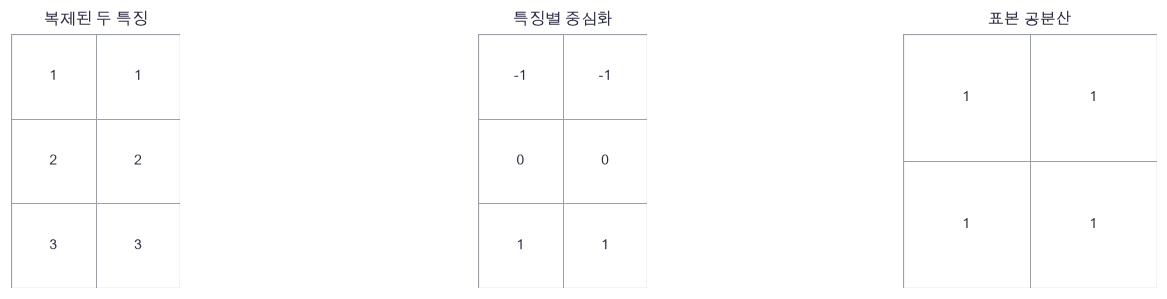

In [3]:
plot_panels([stats_z,stats_center,stats_cov],['복제된 두 특징','특징별 중심화','표본 공분산'])

🔍 **확인** · 분산은 두 차원 모두1이지만 비대각 공분산도1입니다. 특징별 분산만 보면 복제 차원을 놓칩니다.

In [4]:
def covariance_loop(Z):
    """중심화와 N−1 분모 표본 공분산의 반복문입니다. Z:(N,D), N≥2."""
    n,d=Z.shape
    mean=np.zeros(d)
    for j in range(d):
        for i in range(n):
            mean[j]+=Z[i,j]/n
    covariance=np.zeros((d,d))
    for j in range(d):
        for k in range(d):
            for i in range(n):
                covariance[j,k]+=(Z[i,j]-mean[j])*(Z[i,k]-mean[k])/(n-1)
    return mean,covariance

In [5]:
def batch_statistics(Z):
    """중심화·표본 공분산·epsilon 표준편차. N≥2, epsilon=1e−4."""
    assert len(Z)>=2, '표본 공분산을 위해 N이2 이상이어야 합니다'
    C=Z-Z.mean(axis=0,keepdims=True)
    covariance=C.T@C/(len(Z)-1)
    std=np.sqrt(np.diag(covariance)+1e-4)
    return C,covariance,std

In [6]:
# 쓰는 것: stats_z (1절)
mean_loop,cov_loop=covariance_loop(stats_z)
center,cov,std=batch_statistics(stats_z)
np.testing.assert_allclose(mean_loop,[2.,2.])  # 검산: 손계산 평균
np.testing.assert_allclose(cov_loop,np.ones((2,2)))  # 검산: 제곱·교차합2를 N−1=2로 나누기
np.testing.assert_allclose(cov,cov_loop)  # 검산: 반복문 = 벡터화
np.testing.assert_allclose(center.sum(axis=0),0.)  # 검산: 중심화 특징의 관측 합0
try:
    batch_statistics(np.ones((1,2)))
except AssertionError:
    print('N=1은 의도대로 거부합니다.')
else:
    raise AssertionError('N=1 표본 공분산은 거부해야 합니다')

N=1은 의도대로 거부합니다.


### ✏️ 연습 1 · 평균을 뺄 축

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

관측별 표현 Z:(N,D)를 특징별로 중심화하세요.

In [7]:
def exercise_center(Z):
    """관측별 표현 Z:(N,D)를 특징별로 중심화하세요."""

    ### 구현할 내용: 관측별 표현 Z:(N,D)를 특징별로 중심화하세요.
    raise NotImplementedError
    return C

In [8]:
def check_center(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[1.,10.],[3.,14.]])),[[-1.,-2.],[1.,2.]])  # 검산: 평균(2,12)
    print("연습 1: 독립 기준값과 일치합니다.")

run_check(check_center,exercise_center,hint="관측별 표현 Z:(N,D)를 특징별로 중심화하세요.")

☐ exercise_center: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 관측별 표현 Z:(N,D)를 특징별로 중심화하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
C = Z-Z.mean(axis=0,keepdims=True)
```

</details>

## 🔑 2. 특징마다 표준편차 하한을 둡니다

**이 절에서 가져갈 것:** 분산 하한의 값과 기울기는 다른 질문입니다.

모든 과일이 거의 같은 특징이면 두 뷰를 맞히기 쉽지만 구분 정보가 부족합니다. 특징별 표준편차가 γ보다 작을 때 비용을 줍니다.

> **용어** · **hinge**는 기준을 넘으면 비용0, 못 넘으면 차이만큼 비용을 주는 꺾인 함수입니다. 여기서 γ=.5입니다. epsilon은 영분산에서도 나눗셈을 유한하게 합니다.

$$s_d=\sqrt{\Sigma_{dd}+\epsilon},\quad V(Z)=\frac1D\sum_d\max(0,\gamma-s_d),\quad\epsilon=10^{-4},$$
$$\frac{\partial V}{\partial Z_{id}}=-\frac{1[s_d<\gamma]C_{id}}{D(N-1)s_d}.$$

중심화의 합이0이므로 평균 미분의 합이 사라집니다. $s=\gamma$의 비미분점에서는0인 쪽의 부분기울기를 선택합니다. 수치 검산에서는 이 경계를 피합니다. 정확한 상수 입력은 V>0이어도 C=0이므로 기울기가0입니다. 이 비용만으로 완벽한 상수 초기화에서 탈출한다고 주장하지 않습니다.

In [9]:
variance_examples=[np.ones((3,2)),np.array([[-.2,0.],[0.,0.],[.2,0.]]),np.array([[-1.,-1.],[0.,0.],[1.,1.]])]
variance_table=[]
for z in variance_examples:
    c=z-z.mean(axis=0)
    s=np.sqrt((c**2).sum(axis=0)/(len(z)-1)+1e-4)
    variance_table.append(np.r_[s,np.maximum(0.,.5-s)])
variance_table=np.array(variance_table)

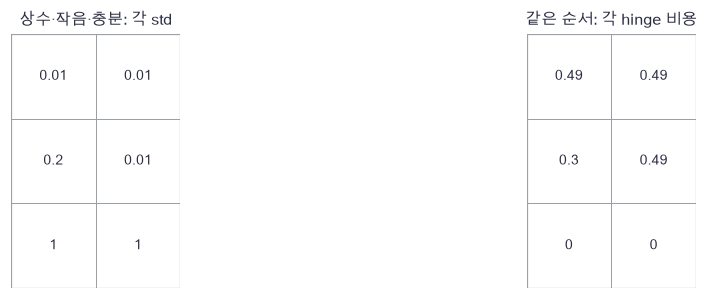

In [10]:
plot_panels([variance_table[:,:2],variance_table[:,2:]],['상수·작음·충분: 각 std','같은 순서: 각 hinge 비용'])

🔍 **확인** · 상수 특징의 평활 표준편차는.01이므로 차원당 비용.49입니다. 비용이 높다는 것과 그 자리의 기울기가 크다는 것은 같지 않습니다.

In [11]:
def variance_loss(Z,floor=.5):
    """특징별 std 하한 hinge와 정확 미분. 경계 std=floor에서는0을 선택합니다."""
    # 쓰는 것: batch_statistics (1절)
    C,covariance,std=batch_statistics(Z)
    active=std<floor
    loss=np.maximum(0.,floor-std).mean()
    gradient=-C*active/(Z.shape[1]*(len(Z)-1)*std)
    return loss,gradient

In [12]:
# 쓰는 것: batch_statistics (1절)
variance_probe=np.array([[-.2,.2],[.1,-.1],[.3,.1]])
variance_value,variance_gradient=variance_loss(variance_probe)
_,_,probe_std=batch_statistics(variance_probe)
assert np.min(np.abs(probe_std-.5))>.01, '수치미분은 hinge 경계에서 충분히 떨어져야 합니다'

In [13]:
def variance_objective():
    """hinge 경계에서 떨어진 분산 하한 미분을 검산합니다."""
    return variance_loss(variance_probe)[0]

In [14]:
np.testing.assert_allclose(variance_gradient,numerical_gradient(variance_objective,variance_probe),atol=1e-8)  # 검산: 분산 항 입력 전체
constant_value,constant_gradient=variance_loss(np.ones((3,2)))
np.testing.assert_allclose(constant_value,.49)  # 검산: .5-sqrt(1e-4)
np.testing.assert_allclose(constant_gradient,0.)  # 검산: 정확한 상수점의 기울기0
print('분산 하한의 미분과 상수 정지점을 확인했습니다.')

분산 하한의 미분과 상수 정지점을 확인했습니다.


### ✏️ 연습 2 · 표준편차가 모자라는 만큼

특징별 std에서 하한 미달 비용의 평균을 계산하세요.

In [15]:
def exercise_hinge(std,floor):
    """특징별 std에서 하한 미달 비용의 평균을 계산하세요."""

    ### 구현할 내용: 특징별 std에서 하한 미달 비용의 평균을 계산하세요.
    raise NotImplementedError
    return loss

In [16]:
def check_hinge(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([.1,.5,.8]),.5),.4/3)  # 검산: 첫 특징만 .4 부족
    print("연습 2: 독립 기준값과 일치합니다.")

run_check(check_hinge,exercise_hinge,hint="특징별 std에서 하한 미달 비용의 평균을 계산하세요.")

☐ exercise_hinge: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 특징별 std에서 하한 미달 비용의 평균을 계산하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
loss = np.maximum(0.,floor-std).mean()
```

</details>

## 🔑 3. 복제 차원은 비대각 공분산에서 드러납니다

**이 절에서 가져갈 것:** 대각 분산을 남기고 비대각 상관만 벌점으로 셉니다.

과일 특징 두 개가 모두 충분히 변해도 같은 숫자를 복제한 것일 수 있습니다. 대각선을 제외한 공분산을 줄입니다.

> **용어** · **비대각(off-diagonal)**은 행 번호와 열 번호가 다른 위치입니다. **비상관(uncorrelated)**은 공분산0이며 일반적으로 통계적 독립과 같지 않습니다.

$O=\Sigma-\operatorname{diag}(\Sigma)$라 두고
$$C_{loss}(Z)=\frac1D\sum_{j\ne k}\Sigma_{jk}^2,\qquad d_Z=\frac4{D(N-1)}C O.$$

대칭인 (j,k)와(k,j)를 **둘 다** 셉니다. 특징 차원 D로만 나누고 D(D−1)로 나누지 않습니다. 중심화 backward는 각 특징에서 dC의 평균을 빼며, 이론적으로 이미0이지만 코드에서도 명시합니다. D=1이면 비대각이 없어 비용0입니다. N−1보다 큰 차원에서 모든 분산 양수와 공분산0을 동시에 만족하기 어려운 표본 rank 제약도 있습니다.

In [17]:
duplicated=np.array([[-1.,-1.],[0.,0.],[1.,1.]])
orthogonal=np.array([[-1.,1.],[0.,-2.],[1.,1.]])
comparison_cov=[]
for z in [duplicated,orthogonal]:
    c=z-z.mean(axis=0)
    comparison_cov.append(c.T@c/2)
comparison_off=[a-np.diag(np.diag(a)) for a in comparison_cov]

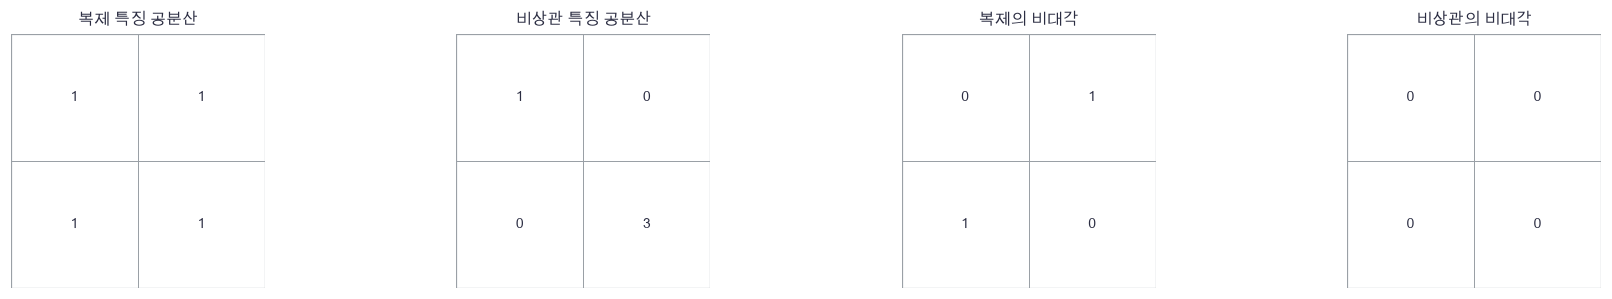

In [18]:
plot_panels(comparison_cov+comparison_off,['복제 특징 공분산','비상관 특징 공분산','복제의 비대각','비상관의 비대각'])

🔍 **확인** · 두 경우 모두 특징이 변하지만 복제에서만 비대각이 남습니다. 이 세 점의 표는 비상관의 손계산 예시이며 모든 미래 관측의 독립성을 증명하지 않습니다.

In [19]:
def covariance_loss(Z):
    """비대각 표본 공분산 제곱합/D와 미분. 양쪽 대칭 원소를 모두 셉니다."""
    # 쓰는 것: batch_statistics (1절)
    C,covariance,std=batch_statistics(Z)
    off=covariance.copy()
    np.fill_diagonal(off,0.)
    loss=(off**2).sum()/Z.shape[1]
    gradient=4*C@off/((len(Z)-1)*Z.shape[1])
    gradient-=gradient.mean(axis=0,keepdims=True)
    return loss,gradient

In [20]:
covariance_probe=np.array([[-.3,.2],[.4,-.1],[.2,.5]])
cov_value,cov_gradient=covariance_loss(covariance_probe)

In [21]:
def covariance_objective():
    """표본 공분산 제곱항 전체 입력 미분을 검산합니다."""
    return covariance_loss(covariance_probe)[0]

In [22]:
# 쓰는 것: duplicated (3절) · orthogonal (3절)
np.testing.assert_allclose(cov_gradient,numerical_gradient(covariance_objective,covariance_probe),atol=1e-8)  # 검산: 공분산 항 입력 전체
np.testing.assert_allclose(covariance_loss(duplicated)[0],1.)  # 검산: (1²+1²)/D=1
np.testing.assert_allclose(covariance_loss(orthogonal)[0],0.)  # 검산: 비대각0
np.testing.assert_allclose(covariance_loss(np.arange(3.)[:,None])[0],0.)  # 검산: D=1 비대각 없음
np.testing.assert_allclose(covariance_loss(covariance_probe+5)[0],cov_value)  # 검산: 특징 평균 이동 불변
print('공분산 미분·복제·D=1·평균 이동을 확인했습니다.')

공분산 미분·복제·D=1·평균 이동을 확인했습니다.


### ✏️ 연습 3 · 대각선 벌점 제외

비대각 제곱합을 특징 차원 D로 나누세요.

In [23]:
def exercise_offdiag(covariance):
    """비대각 제곱합을 특징 차원 D로 나누세요."""
    off = covariance.copy()
    ### 구현할 내용: 비대각 제곱합을 특징 차원 D로 나누세요.
    raise NotImplementedError
    return penalty

In [24]:
def check_offdiag(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[4.,2.],[2.,9.]])),4.)  # 검산: (4+4)/2
    print("연습 3: 독립 기준값과 일치합니다.")

run_check(check_offdiag,exercise_offdiag,hint="비대각 제곱합을 특징 차원 D로 나누세요.")

☐ exercise_offdiag: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 비대각 제곱합을 특징 차원 D로 나누세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
np.fill_diagonal(off,0.)
penalty = (off**2).sum()/len(off)
```

</details>

## 🔑 4. 세 항을 합하고 공유 표현기까지 미분합니다

**이 절에서 가져갈 것:** 두 뷰 모두 미분하되 목적항마다 다른 분모를 유지합니다.

같은 과일의 두 촬영 표현을 $A,B:(N,D)$라고 합니다. 이번에는 teacher나 stop-gradient 없이 같은 encoder의 양쪽 경로를 모두 갱신합니다.

$$I=\operatorname{mean}_{i,d}(A-B)^2,\quad L=\alpha I+\frac\beta2[V(A)+V(B)]+\frac\eta2[C_{loss}(A)+C_{loss}(B)].$$

기본 $(\alpha,\beta,\eta)=(5,5,1)$입니다. 정렬은 ND로 평균하고 분산·공분산은 각 정의의 D와N−1을 유지합니다. $d_AI=2(A-B)/(ND)$, $d_BI=-d_AI$입니다. 다른 항의 기여를 가중해 더합니다.

encoder는 $H=\tanh(XW+b)$, $Z=HV+c$입니다. dZ를 받아 $dV=H^TdZ$, $dc=\sum dZ$, $dU=(dZV^T)\odot(1-H^2)$, $dW=X^TdU$, $db=\sum dU$, $dX=dUW^T$를 계산합니다. 입력은4차원, 은닉8, 표현3차원입니다. 여기서는 행 정규화를 하지 않습니다. 분산 하한이 크기 정보를 직접 사용하기 때문입니다.

> **코드** · `np.concatenate([dA,dB],axis=0)`는 같은 encoder의 두 뷰 미분을 합할 준비입니다. 이름별 파라미터 사전과 `.copy()`는 초기값을 조건마다 동일하게 유지합니다.

In [25]:
# 쓰는 것: covariance_loss (3절) · variance_loss (2절)
term_a=np.array([[-.2,-.2],[0.,0.],[.2,.2]])
term_b=term_a+.1
term_align=np.mean((term_a-term_b)**2)
term_variance=variance_loss(term_a)[0]
term_cov=covariance_loss(term_a)[0]
term_table=np.array([[term_align,term_variance,term_cov]])
weighted_table=term_table*np.array([5.,5.,1.])

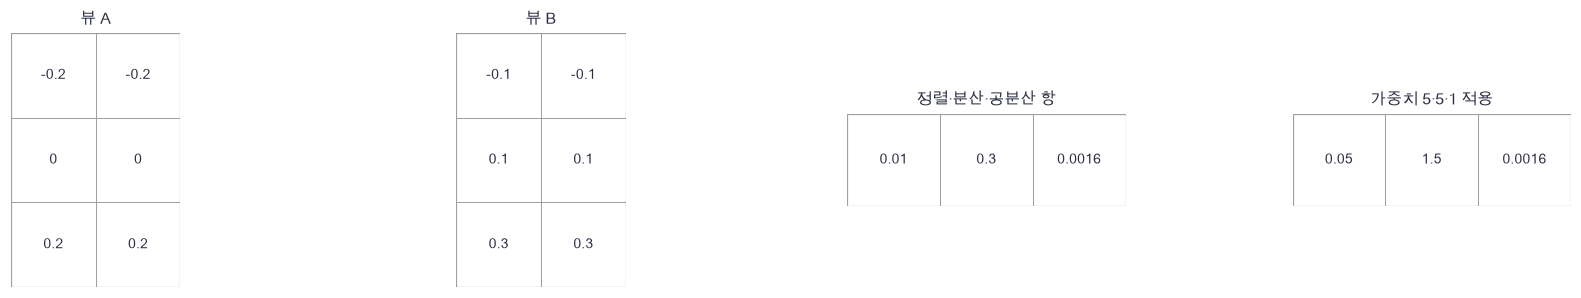

In [26]:
plot_panels([term_a,term_b,term_table,weighted_table],['뷰 A','뷰 B','정렬·분산·공분산 항','가중치 5·5·1 적용'])

🔍 **확인** · 일정한.1 차이는 정렬 항을 남기지만 중심화한 통계는 같으므로 두 뷰의 분산·공분산 비용은 같습니다.

In [27]:
def regularized_loss(A,B,weights=(5.,5.,1.)):
    """정렬+양쪽 분산·공분산 평균. A,B:(N,D) → total,dA,dB,3항."""
    # 쓰는 것: covariance_loss (3절) · variance_loss (2절)
    align=np.mean((A-B)**2)
    da=2*(A-B)/A.size
    va,dva=variance_loss(A)
    vb,dvb=variance_loss(B)
    ca,dca=covariance_loss(A)
    cb,dcb=covariance_loss(B)
    terms=np.array([align,(va+vb)/2,(ca+cb)/2])
    alpha,beta,gamma=weights
    dA=alpha*da+.5*beta*dva+.5*gamma*dca
    dB=-alpha*da+.5*beta*dvb+.5*gamma*dcb
    return np.dot(weights,terms),dA,dB,terms

In [28]:
def init_encoder(seed=390,hidden=8,out=3):
    """4→H→D tanh 표현기. 마지막 출력은 정규화 전 실수입니다."""
    rng=np.random.default_rng(seed)
    return {'W':rng.normal(0,.3,(4,hidden)),'b':np.zeros(hidden),
            'V':rng.normal(0,.3,(hidden,out)),'c':np.zeros(out)}

In [29]:
def encode(X,p):
    """H=tanh(XW+b), Z=HV+c. X:(N,4) → Z:(N,D), cache."""
    H=np.tanh(X@p['W']+p['b'])
    return H@p['V']+p['c'],(X,H)

In [30]:
def encode_backward(dZ,cache,p):
    """공유 표현기 모든 파라미터와 연속 입력의 미분입니다."""
    X,H=cache
    dU=(dZ@p['V'].T)*(1-H**2)
    grads={'V':H.T@dZ,'c':dZ.sum(axis=0),'W':X.T@dU,'b':dU.sum(axis=0)}
    return grads,dU@p['W'].T

In [31]:
# 쓰는 것: batch_statistics (1절) · regularized_loss (4절)
probe=init_encoder(417,hidden=3,out=2)
probe_x=np.random.default_rng(418).normal(size=(6,4))
probe_z,probe_cache=encode(probe_x,probe)
probe_value,dA,dB,probe_terms=regularized_loss(probe_z[:3],probe_z[3:])
analytic,analytic_x=encode_backward(np.concatenate([dA,dB]),probe_cache,probe)
for part in [probe_z[:3],probe_z[3:]]:
    assert np.min(np.abs(batch_statistics(part)[2]-.5))>.01, '전체 미분 probe도 hinge 경계를 피해야 합니다'

In [32]:
def full_objective():
    """세 목적항과 공유 encoder를 함께 중심차분합니다."""
    # 쓰는 것: regularized_loss (4절)
    Z,_=encode(probe_x,probe)
    return regularized_loss(Z[:3],Z[3:])[0]

In [33]:
errors=[]
for key in probe:
    numeric=numerical_gradient(full_objective,probe[key])
    np.testing.assert_allclose(analytic[key],numeric,atol=2e-7,rtol=3e-5)  # 검산: 모든 encoder 파라미터
    errors.append(np.max(np.abs(analytic[key]-numeric)))
numeric_x=numerical_gradient(full_objective,probe_x)
np.testing.assert_allclose(analytic_x,numeric_x,atol=2e-7,rtol=3e-5)  # 검산: 두 뷰 입력 전체
print('모든 파라미터·입력 최대 절대오차',max(errors+[np.max(np.abs(analytic_x-numeric_x))]))

모든 파라미터·입력 최대 절대오차 4.4437341133185537e-10


### ✏️ 연습 4 · 정렬 항의 ND 분모

모든 관측·특징을 평균한 제곱거리의 A 미분을 반환하세요.

In [34]:
def exercise_align_gradient(A,B):
    """모든 관측·특징을 평균한 제곱거리의 A 미분을 반환하세요."""

    ### 구현할 내용: 모든 관측·특징을 평균한 제곱거리의 A 미분을 반환하세요.
    raise NotImplementedError
    return dA

In [35]:
def check_align_gradient(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.ones((2,3)),np.zeros((2,3))),np.full((2,3),1/3))  # 검산: 2/(N*D)=1/3
    print("연습 4: 독립 기준값과 일치합니다.")

run_check(check_align_gradient,exercise_align_gradient,hint="모든 관측·특징을 평균한 제곱거리의 A 미분을 반환하세요.")

☐ exercise_align_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 모든 관측·특징을 평균한 제곱거리의 A 미분을 반환하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dA = 2*(A-B)/A.size
```

</details>

## 🔑 5. 목적항을 빼 보며 실제 표현을 평가합니다

**이 절에서 가져갈 것:** 서로 다른 총손실을 순위로 비교하지 말고 공통 통계와 독립 probe를 봅니다.

앞 두 열에 품종 상태, 뒤 두 열에 배경이 있는 과일을 두 번 촬영합니다. 배경만 재추출하고 상태는 보존합니다. train512/valid64/test256(seed411/412/413), 초기410, 학습난수414, fixedvalid뷰415를 미리 정합니다.

같은67파라미터 encoder, B32,350갱신, Adam lr.005로 세 조건 `(α,β,η)=(5,0,0),(5,5,0),(5,5,1)`을 학습합니다. 각각 정렬만, 정렬+분산, 전체 목적입니다. validation은 관찰만 하고 선택에 쓰지 않습니다. 한 seed의 작은 제거 실험이며 평가 후 설정을 바꾸지 않습니다.

Adam은 .9/.999 모멘트를 bias 보정하고 epsilon1e−8로 갱신합니다. 라벨은 표현 학습에 넣지 않습니다. 평가에서는 초기/세 모델의 **원래 표현 Z**를 동결하고 train512라벨로0초기 선형3클래스 probe를300전배치 SGD lr.15로 학습합니다. CE의 미분 `(P-onehot)/N`과 `Z.T@G`를 씁니다. 조건마다 별도 표준화는 하지 않습니다. 그러므로 probe는 표현의 크기와 고정 최적화 예산에도 영향을 받는 제한된 평가입니다.

통계는 test의 특징별 평균·표본 표준편차 최소값·비대각 공분산 벌점·순환 이동한 다른 관측과의 제곱거리와 probe정확도입니다. test분모는256입니다. 총 목적 대신 세 항을 공통 정의로 각각 출력합니다.

> **코드** · `choice(...,replace=False)`는 배치 내 같은 원본의 중복을 피합니다. `np.roll`은 다른 관측 쌍을 고정하는 순환 이동입니다. `history[:,[0,1]]`은 step과 첫 목적항 두 열만 고릅니다.

In [36]:
# 쓰는 것: variance_loss (2절)
weights_table=np.array([[5.,0.,0.],[5.,5.,0.],[5.,5.,1.]])
plan=np.array([[512,411],[64,412],[256,413]])
collapsed_terms=np.array([[0.,variance_loss(np.ones((3,2)))[0],0.]])

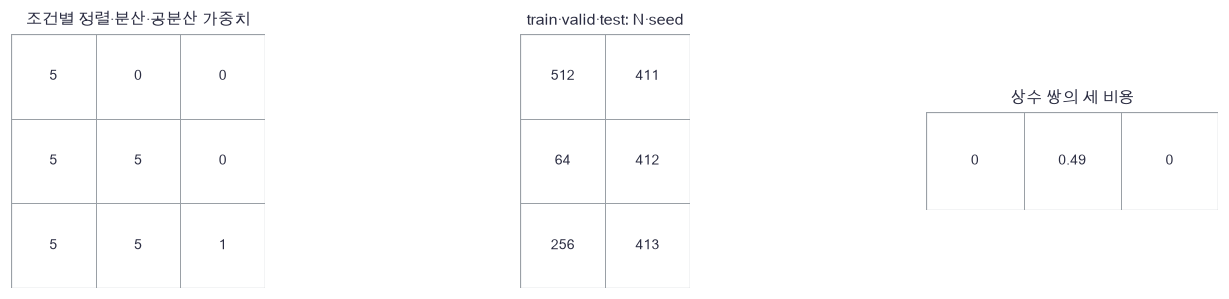

In [37]:
plot_panels([weights_table,plan,collapsed_terms],['조건별 정렬·분산·공분산 가중치','train·valid·test: N·seed','상수 쌍의 세 비용'])

🔍 **확인** · 같은 상수 쌍도 분산 항을 켠 목적에서는 양의 비용입니다. 정확한 상수는 여전히 정지점이므로 실제 학습은 고정한 무작위 초기값에서 시작합니다.

In [38]:
def make_data(n,seed):
    """세 품종의 상태 2차원과 독립 배경 2차원 합성 관측을 만듭니다."""
    rng=np.random.default_rng(seed)
    y=rng.integers(0,3,n)
    angles=2*np.pi*y/3
    state=np.column_stack([np.cos(angles),np.sin(angles)])+.2*rng.normal(size=(n,2))
    nuisance=rng.normal(size=(n,2))
    return np.concatenate([state,nuisance],axis=1),y

In [39]:
def two_views(X,rng):
    """상태는 고정하고 두 뷰의 배경을 독립 재추출합니다. → (2N,4)."""
    A=X.copy()
    B=X.copy()
    A[:,2:]=rng.normal(size=(len(X),2))
    B[:,2:]=rng.normal(size=(len(X),2))
    return np.concatenate([A,B],axis=0)

In [40]:
def adam_step(p,g,m,v,step,lr=.01):
    """Adam 모멘트·bias 보정을 적용합니다."""
    for k in p:
        m[k]=.9*m[k]+.1*g[k]
        v[k]=.999*v[k]+.001*g[k]**2
        p[k]-=lr*(m[k]/(1-.9**step))/(np.sqrt(v[k]/(1-.999**step))+1e-8)

In [41]:
def train_regularized(X,valid_views,initial,weights):
    """같은 초기·뷰 난수·350 Adam 갱신으로 목적항의 유무를 비교합니다."""
    # 쓰는 것: encode (4절) · encode_backward (4절) · regularized_loss (4절)
    # 1. 표현기와 optimizer 상태·학습 난수입니다.
    p={k:a.copy() for k,a in initial.items()}
    m={k:np.zeros_like(a) for k,a in p.items()}
    v={k:np.zeros_like(a) for k,a in p.items()}
    rng=np.random.default_rng(414)
    history=[]
    # 2. 두 뷰의 역전파를 한 공유 encoder에 합합니다.
    for step in range(1,351):
        idx=rng.choice(len(X),32,replace=False)
        views=two_views(X[idx],rng)
        Z,cache=encode(views,p)
        loss,dA,dB,terms=regularized_loss(Z[:32],Z[32:],weights)
        grads,_=encode_backward(np.concatenate([dA,dB],axis=0),cache,p)
        adam_step(p,grads,m,v,step,lr=.005)
        if step%35==0:
            Z,_=encode(valid_views,p)
            half=len(Z)//2
            value,_,_,terms=regularized_loss(Z[:half],Z[half:],weights)
            history.append([step,*terms])
    return p,np.array(history)

In [42]:
def multiclass_loss(logits,y):
    """안정적인 표본 평균 CE와 logit 미분. (N,C), (N,) → scalar,(N,C)."""
    shifted=logits-logits.max(axis=1,keepdims=True)
    expS=np.exp(shifted)
    P=expS/expS.sum(axis=1,keepdims=True)
    loss=np.mean(np.log(expS.sum(axis=1))-shifted[np.arange(len(y)),y])
    G=P.copy()
    G[np.arange(len(y)),y]-=1
    return loss,G/len(y)

In [43]:
def fit_probe(features,y):
    """고정 표현 위의 선형 3클래스 probe만 300회 전배치 SGD 학습합니다."""
    W=np.zeros((features.shape[1],3))
    b=np.zeros(3)
    for step in range(300):
        loss,G=multiclass_loss(features@W+b,y)
        W-=.15*features.T@G
        b-=.15*G.sum(axis=0)
    return W,b

In [44]:
# 쓰는 것: init_encoder (4절) · make_data (5절) · two_views (5절)
train_x,train_y=make_data(512,411)
valid_x,valid_y=make_data(64,412)
test_x,test_y=make_data(256,413)
valid_views=two_views(valid_x,np.random.default_rng(415))
initial=init_encoder(410)
settings=[('정렬만',(5.,0.,0.)),('정렬+분산',(5.,5.,0.)),('전체',(5.,5.,1.))]
models=[]
histories=[]
for label,weights in settings:
    fitted,history=train_regularized(train_x,valid_views,initial,weights)
    models.append(fitted)
    histories.append(history)
print('실제 학습: 조건당350갱신·67파라미터')

실제 학습: 조건당350갱신·67파라미터


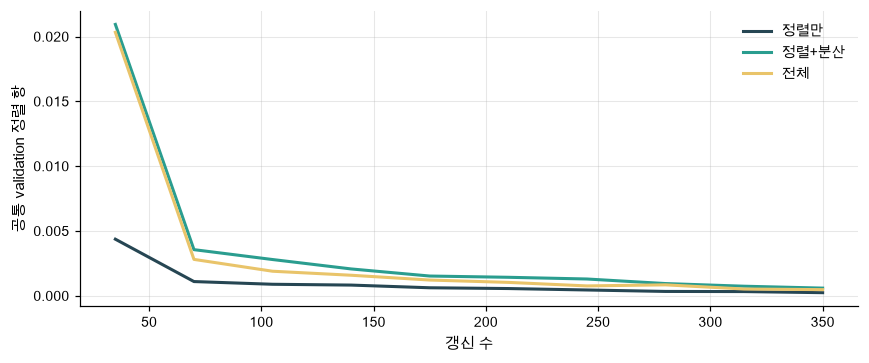

In [45]:
plot_curves([h[:,[0,1]] for h in histories],[s[0] for s in settings],'공통 validation 정렬 항')

In [46]:
# 쓰는 것: batch_statistics (1절) · covariance_loss (3절) · encode (4절)
report=[]
for p in [initial]+models:
    frozen={k:a.copy() for k,a in p.items()}
    train_z,_=encode(train_x,p)
    test_z,_=encode(test_x,p)
    Wq,bq=fit_probe(train_z,train_y)
    accuracy=np.mean((test_z@Wq+bq).argmax(axis=1)==test_y)
    _,cov,std=batch_statistics(test_z)
    distance=((test_z-np.roll(test_z,1,axis=0))**2).sum(axis=1).mean()
    report.append([accuracy,test_z.mean(),std.min(),covariance_loss(test_z)[0],distance])
    for key in p:
        np.testing.assert_array_equal(p[key],frozen[key])  # 검산: probe 중 encoder 불변
report=np.array(report)
print('초기/정렬/정렬+분산/전체 · 정확도,평균,최소std,공분산비용,다른거리',np.round(report,4))
print('세 학습 조건의 마지막 valid 공통항 [정렬,분산,공분산]')
for (label,_),h in zip(settings,histories):
    print(label,np.round(h[-1,1:],5))

초기/정렬/정렬+분산/전체 · 정확도,평균,최소std,공분산비용,다른거리 [[ 7.9690e-01 -2.7200e-02  3.0680e-01  8.4000e-03  1.2448e+00]
 [ 1.0000e+00  2.3100e-02  1.3600e-01  3.0000e-04  1.9540e-01]
 [ 1.0000e+00 -3.7900e-02  6.7320e-01  1.6490e-01  2.9221e+00]
 [ 1.0000e+00  6.3000e-03  5.2000e-01  4.6600e-02  1.9267e+00]]
세 학습 조건의 마지막 valid 공통항 [정렬,분산,공분산]
정렬만 [2.4000e-04 3.2697e-01 4.3000e-04]
정렬+분산 [0.0006  0.      0.23615]
전체 [0.00048 0.      0.04683]


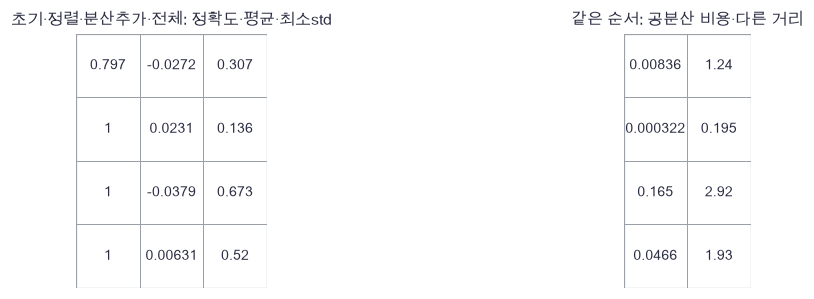

In [47]:
plot_panels([report[:,:3],report[:,3:]],['초기·정렬·분산추가·전체: 정확도·평균·최소std','같은 순서: 공분산 비용·다른 거리'])

🔍 **확인** · 위는 실제 고정 실행의 관측값입니다. 정렬만의 작은 거리나 총손실만으로 성공을 판단하지 마세요. 분산 추가가 특징 복제를 남기는지, 공분산 항이 그 중복을 줄이는지 공통 비용으로 확인하세요. 비대각 비용 감소도 품종 정확도 증가를 보장하지 않습니다.

### ✏️ 연습 5 · 조건별 총목적 구성

정렬·양쪽 평균분산·양쪽 평균공분산 세 항에 가중치를 곱해 합하세요.

In [48]:
def exercise_weighted_terms(terms,weights):
    """정렬·양쪽 평균분산·양쪽 평균공분산 세 항에 가중치를 곱해 합하세요."""

    ### 구현할 내용: 정렬·양쪽 평균분산·양쪽 평균공분산 세 항에 가중치를 곱해 합하세요.
    raise NotImplementedError
    return total

In [49]:
def check_weighted_terms(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([.2,.3,.4]),np.array([5.,5.,1.])),2.9)  # 검산: 1+1.5+.4
    print("연습 5: 독립 기준값과 일치합니다.")

run_check(check_weighted_terms,exercise_weighted_terms,hint="정렬·양쪽 평균분산·양쪽 평균공분산 세 항에 가중치를 곱해 합하세요.")

☐ exercise_weighted_terms: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 정렬·양쪽 평균분산·양쪽 평균공분산 세 항에 가중치를 곱해 합하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
total = np.dot(terms,weights)
```

</details>

## ✏️ 끝 연습 · 분모·경계·특징 수를 바꿉니다

### ✏️ 연습 A · 표본 공분산의 분모

N≥2에서 표본 공분산을 계산하세요.

In [50]:
def exercise_sample_cov(Z):
    """N≥2에서 표본 공분산을 계산하세요."""
    C = Z-Z.mean(axis=0,keepdims=True)
    ### 구현할 내용: N≥2에서 표본 공분산을 계산하세요.
    raise NotImplementedError
    return cov

In [51]:
def check_sample_cov(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[1.],[3.]])),[[2.]])  # 검산: N=2에서 제곱합2/(N−1)
    print("연습 A: 독립 기준값과 일치합니다.")

run_check(check_sample_cov,exercise_sample_cov,hint="N≥2에서 표본 공분산을 계산하세요.")

☐ exercise_sample_cov: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: N≥2에서 표본 공분산을 계산하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
cov = C.T@C/(len(Z)-1)
```

</details>

### ✏️ 연습 B · 하한 미달 특징만 미분

중심화 C와 평활 표준편차에서 분산 하한의 입력 미분을 만드세요.

In [52]:
def exercise_std_gradient(C,std,floor):
    """중심화 C와 평활 표준편차에서 분산 하한의 입력 미분을 만드세요."""
    N,D = C.shape
    ### 구현할 내용: 중심화 C와 평활 표준편차에서 분산 하한의 입력 미분을 만드세요.
    raise NotImplementedError
    return gradient

In [53]:
def check_std_gradient(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[-1.,-1.],[1.,1.]]),np.array([.5,2.]),1.),[[1.,0.],[-1.,0.]])  # 검산: 첫 특징만 활성
    print("연습 B: 독립 기준값과 일치합니다.")

run_check(check_std_gradient,exercise_std_gradient,hint="중심화 C와 평활 표준편차에서 분산 하한의 입력 미분을 만드세요.")

☐ exercise_std_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 중심화 C와 평활 표준편차에서 분산 하한의 입력 미분을 만드세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient = -C*(std<floor)/(D*(N-1)*std)
```

</details>

### ✏️ 연습 C · 양쪽 뷰의 정렬 미분

정렬 항에서 A로 가는 미분을 알 때 B로 가는 미분을 반환하세요.

In [54]:
def exercise_symmetry(dA):
    """정렬 항에서 A로 가는 미분을 알 때 B로 가는 미분을 반환하세요."""

    ### 구현할 내용: 정렬 항에서 A로 가는 미분을 알 때 B로 가는 미분을 반환하세요.
    raise NotImplementedError
    return dB

In [55]:
def check_symmetry(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_array_equal(candidate(np.array([[1.,-2.],[3.,0.]])),[[-1.,2.],[-3.,0.]])  # 검산: 차이의 반대 경로
    print("연습 C: 독립 기준값과 일치합니다.")

run_check(check_symmetry,exercise_symmetry,hint="정렬 항에서 A로 가는 미분을 알 때 B로 가는 미분을 반환하세요.")

☐ exercise_symmetry: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 정렬 항에서 A로 가는 미분을 알 때 B로 가는 미분을 반환하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
dB = -dA
```

</details>

### ✏️ 연습 D · 특징 단위를 바꾸면 공분산은

좌표 j를 scales[j]배할 때 공분산 양축을 보정하세요. 단위 변화는 벌점 크기도 바꿉니다.

In [56]:
def exercise_feature_scaling(covariance,scales):
    """좌표 j를 scales[j]배할 때 공분산 양축을 보정하세요. 단위 변화는 벌점 크기도 바꿉니다."""

    ### 구현할 내용: 좌표 j를 scales[j]배할 때 공분산 양축을 보정하세요. 단위 변화는 벌점 크기도 바꿉니다.
    raise NotImplementedError
    return changed

In [57]:
def check_feature_scaling(candidate):
    """작은 독립 기준값과 비교합니다."""
    np.testing.assert_allclose(candidate(np.array([[1.,.5],[.5,4.]]),np.array([2.,-1.])),[[4.,-1.],[-1.,4.]])  # 검산: 좌표별 단위 곱
    print("연습 D: 독립 기준값과 일치합니다.")

run_check(check_feature_scaling,exercise_feature_scaling,hint="좌표 j를 scales[j]배할 때 공분산 양축을 보정하세요. 단위 변화는 벌점 크기도 바꿉니다.")

☐ exercise_feature_scaling: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 좌표 j를 scales[j]배할 때 공분산 양축을 보정하세요. 단위 변화는 벌점 크기도 바꿉니다.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
changed = covariance*scales[:,None]*scales[None,:]
```

</details>

### ✏️ 준비도 질문

- **설명:** 정렬·분산·공분산이 각각 어떤 실패를 다루며, 양의 벌점이 항상 탈출 기울기를 뜻하지 않는 이유는 무엇인가요? → 1–3절
- **수식:** N−1·D·ND 분모와 공분산 미분의4, 두 뷰의1/2를 쓸 수 있나요? → 1–4절
- **구현:** hinge 경계를 피한 전체 파라미터·양쪽 입력 검산을 재현할 수 있나요? → 4절
- **변형 검산:** N=1·D=1·상수·복제·특징 단위 변경을 검사할 수 있나요? → 1–3절, 연습 A–D

### 📎 원전과 다음 연결

[VICReg 원논문, Bardes et al., 2022](https://arxiv.org/abs/2105.04906)은 정렬·분산·공분산 제약으로 표현 학습을 구성합니다. 이 노트북은 원리를 작은 tanh 표현기에 적용하며 원논문의 전체 encoder·projector·계수·이미지 benchmark를 복제하지 않습니다. 원문과 별개로 이 구현의 분모·epsilon·하한·가중치를 위에서 명시했습니다. 42번에서는 일부 입력을 가리고 원래 관측을 맞히는 목적, 43번에서는 가린 영역의 교사 표현을 맞히는 목적을 비교합니다.